# Faster R-CNN -- large, class/country-balanced dataset (notebook 10)

Direct counterpart to notebook 09 (YOLOv8n on the same dataset). Same dataset
(`data/processed/RDD2022_4classes_large`, 4,291/597/592 images), same imgsz
(640), same effective batch size (16) -- the matched-parameter comparison
this project has used at every dataset-size iteration (nb03 vs nb07 on small,
nb05 vs nb08 on medium, this vs nb09 on large). This is the run that
completes **H1** (YOLOv8 mAP within 2% of Faster R-CNN, with lower
computational complexity) at the final iteration's data scale.

## A note on runtime, worth keeping for the thesis

Getting a reliable per-epoch time estimate for this run took three smoke
tests, not one -- worth documenting honestly since it's itself a small piece
of evidence for H1's "computational complexity" comparison:

| Test | Config | Result |
|---|---|---|
| 1 | batch=8, workers=0 | 1444s/epoch (run right after the YOLOv8n large-dataset training had just finished) |
| 2 | batch=4, workers=2 | 1172s/epoch (run immediately after test 1, no cooldown) |
| 3 | batch=4, workers=2, GPU cooled, no other processes | **445s/epoch** |

Image size and annotation-density differences between the medium and large
datasets were checked and ruled out as the cause (large dataset images are
only ~24% more pixels before the internal resize to 640, and annotation
density is essentially identical: 2.52 vs 2.65 boxes/image). The 2.6-3.2x
slowdown in tests 1-2 is attributed to thermal/system-load contamination from
running consecutive GPU-intensive jobs back-to-back on a laptop Max-Q GPU,
not a property of the dataset itself. Test 3's 445s/epoch is the number this
notebook's config is based on -- still, this run measures and reports its
*own* actual total wall-clock time below rather than relying on the estimate,
since a real multi-hour run can still warm up gradually in ways a single
clean epoch doesn't capture.

Config: batch=4, accum_steps=4 (effective batch 16, matching notebook 09's
YOLOv8n batch=16), epochs=100 (max), patience=20 -- same methodology as every
prior iteration. Peak GPU memory measured at ~2.8GB across all three tests,
comfortably within the 8GB budget regardless of the timing variance.

In [1]:
import sys
import time
from pathlib import Path

import torch
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append("..")
from src.training.fasterrcnn import (
    build_model, build_dataloaders, TrainConfig, get_device, fit, evaluate, CLASS_NAMES,
)

torch.manual_seed(42)

## Dataset

Same split used for the YOLOv8n large-dataset run (notebook 09).

In [2]:
DATASET_DIR = Path("../data/processed/RDD2022_4classes_large")
BATCH_SIZE = 4   # real per-step batch (kept small for GPU memory)
WORKERS = 2

train_loader, val_loader, test_loader = build_dataloaders(DATASET_DIR, batch_size=BATCH_SIZE, workers=WORKERS)

print(f"train: {len(train_loader.dataset)} images ({len(train_loader)} batches)")
print(f"val:   {len(val_loader.dataset)} images ({len(val_loader)} batches)")
print(f"test:  {len(test_loader.dataset)} images ({len(test_loader)} batches)")

train: 4291 images (1073 batches)
val:   597 images (150 batches)
test:  592 images (148 batches)


## Model

Faster R-CNN, ResNet50-FPN v2 backbone, COCO-pretrained, head replaced for 4 damage classes + background. Internal resize capped to imgsz=640, matching YOLO.

In [3]:
DEVICE = get_device()
print("Device:", DEVICE)

IMGSZ = 640
model = build_model(imgsz=IMGSZ)
model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {total_params / 1e6:.1f}M")
print(f"Internal resize: {model.transform.min_size} / {model.transform.max_size}")

Device: cuda
Parameters: 43.3M
Internal resize: (640,) / 640


## Training configuration

Matched to notebook 08 (Faster R-CNN, medium dataset) and to notebook 09
(YOLOv8n, this same large dataset):

| | YOLOv8n (nb09) | Faster R-CNN (this notebook) |
|---|---|---|
| epochs (max) | 100 | 100 |
| patience | 20 | 20 (on val_loss) |
| imgsz | 640 | 640 |
| effective batch | 16 | 16 (4 x 4 grad-accum steps) |
| measured per-epoch time | ~49s | ~445s (clean-conditions measurement) |

In [4]:
cfg = TrainConfig(
    epochs=100,
    patience=20,
    learning_rate=0.005,
    momentum=0.9,
    weight_decay=0.0005,
    step_size=30,
    gamma=0.1,
    accum_steps=4,      # 4 * 4 = effective batch 16
    amp=True,
)
print(cfg)

TrainConfig(epochs=100, patience=20, learning_rate=0.005, momentum=0.9, weight_decay=0.0005, step_size=30, gamma=0.1, accum_steps=4, amp=True, grad_clip=5.0)


## Training loop

Checkpoints (`last.pt`, `best.pt` by lowest val_loss) and `results.csv`
(includes a `time_s` column per epoch) are saved under
`models/fasterrcnn_large/`. Total wall-clock time is measured explicitly here
-- the actual number to cite in the thesis, not the pre-run estimate.

In [5]:
RUN_DIR = Path("../models/fasterrcnn_large")

run_start = time.time()
history_df = fit(model, train_loader, val_loader, DEVICE, RUN_DIR, cfg=cfg, progress=True)
total_wall_seconds = time.time() - run_start

print(f"Epochs run: {len(history_df)} (max was {cfg.epochs}, patience {cfg.patience})")
print(f"Total wall-clock training time: {total_wall_seconds/3600:.2f} hours ({total_wall_seconds/60:.1f} minutes)")
print(f"Sum of per-epoch time_s (train+val only, excludes setup): {history_df['time_s'].sum()/3600:.2f} hours")
print(f"Mean epoch time: {history_df['time_s'].mean():.1f}s")

# Saved alongside results.csv so this number survives independently of the
# notebook's own output cells -- the thesis-citable runtime metric for H1's
# "computational complexity" comparison against YOLOv8n (notebook 09: 1.36
# hours total, 100/100 epochs, no early stop).
with open(RUN_DIR / "runtime_summary.txt", "w", encoding="utf-8") as f:
    f.write(f"epochs_run={len(history_df)}\n")
    f.write(f"epochs_max={cfg.epochs}\n")
    f.write(f"patience={cfg.patience}\n")
    f.write(f"total_wall_clock_hours={total_wall_seconds/3600:.4f}\n")
    f.write(f"mean_epoch_seconds={history_df['time_s'].mean():.2f}\n")
    f.write(f"effective_batch_size=16\n")
    f.write(f"train_images={len(train_loader.dataset)}\n")

history_df

epochs:   0%|          | 0/100 [00:00<?, ?epoch/s]

Early stopping: no val_loss improvement for 20 epochs (epoch 22).
Epochs run: 22 (max was 100, patience 20)
Total wall-clock training time: 4.16 hours (249.9 minutes)
Sum of per-epoch time_s (train+val only, excludes setup): 4.16 hours
Mean epoch time: 681.1s


,epoch,train_loss,val_loss,time_s
0,1,0.493053,0.441380,448.189145
1,2,0.371710,0.401248,929.053543
2,3,0.340244,0.432914,2559.395054
3,4,0.315970,0.440788,453.022663
4,5,0.289802,0.448035,460.042657
5,6,0.267601,0.468631,463.739924
6,7,0.244999,0.485370,2614.916307
7,8,0.230107,0.477857,452.942919
8,9,0.214403,0.487325,461.725886
9,10,0.198182,0.515076,468.961274


## Loss curve

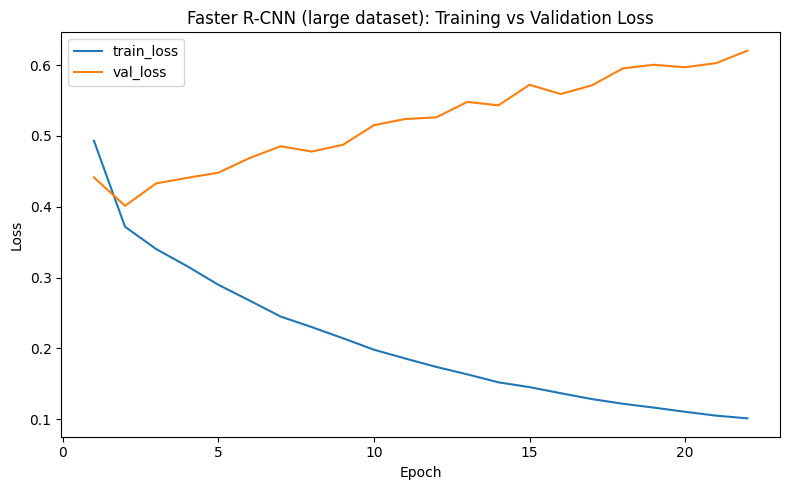

In [6]:
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], label="train_loss")
plt.plot(history_df["epoch"], history_df["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Faster R-CNN (large dataset): Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.savefig("fasterrcnn_large_loss_curve.png", bbox_inches="tight")
plt.show()

## Test-set evaluation

Loads `best.pt` and computes the same metric set as notebooks 07/08:
precision, recall, F1 at the best-F1 confidence threshold, plus mAP50 /
mAP50-95 (via `torchmetrics`) and average inference time -- the inference
time is the other half of H1's "lower computational complexity" comparison,
alongside training wall-clock time above.

In [7]:
model.load_state_dict(torch.load(RUN_DIR / "best.pt", map_location=DEVICE))

results = evaluate(model, test_loader, DEVICE, iou_threshold=0.5)

print(f"Precision:           {results['precision']:.3f}  (at confidence >= {results['best_threshold']})")
print(f"Recall:              {results['recall']:.3f}")
print(f"F1:                  {results['f1']:.3f}")
print(f"mAP50:                {results['mAP50']:.4f}")
print(f"mAP50-95:             {results['mAP50-95']:.4f}")
print(f"Avg inference time:  {results['avg_inference_ms']:.1f} ms/image")

Precision:           0.434  (at confidence >= 0.55)
Recall:              0.379
F1:                  0.404
mAP50:                0.3733
mAP50-95:             0.1855
Avg inference time:  87.2 ms/image


In [8]:
raw = results["raw_torchmetrics"]
seen = raw["classes"].tolist()
rows = []
for cid, cname in CLASS_NAMES.items():
    if cid in seen:
        idx = seen.index(cid)
        rows.append({
            "class": cname,
            "mAP50-95": round(raw["map_per_class"][idx].item(), 4),
            "mean_recall@100": round(raw["mar_100_per_class"][idx].item(), 4),
        })

per_class_df = pd.DataFrame(rows)
per_class_df

,class,mAP50-95,mean_recall@100
0,D00_Longitudinal_Crack,0.1313,0.3035
1,D10_Transverse_Crack,0.1644,0.3226
2,D20_Alligator_Crack,0.1693,0.3624
3,D40_Pothole,0.2772,0.5088


## H1 -- model comparison (YOLOv8n vs Faster R-CNN, large dataset)

H1: "YOLOv8 will achieve detection accuracy (mAP) within 2% of Faster R-CNN,
while maintaining lower computational complexity."

Both figures needed for this hypothesis: accuracy (mAP50-95) and
computational complexity (training time + inference time), same dataset,
same imgsz, same effective batch size.

In [9]:
YOLO_MAP50 = 0.5481
YOLO_MAP50_95 = 0.3002
YOLO_TRAINING_HOURS = 1.36  # notebook 09: 100/100 epochs, no early stop
YOLO_INFERENCE_MS = 3.4     # notebook 09 TEST-split speed line: "3.4ms inference" (matches this notebook evaluating on test too)

frcnn_map50 = results["mAP50"]
frcnn_map50_95 = results["mAP50-95"]
frcnn_training_hours = total_wall_seconds / 3600

map50_95_diff_pct = (frcnn_map50_95 - YOLO_MAP50_95) * 100  # percentage points, mAP scale is already 0-1

h1_df = pd.DataFrame([
    {
        "model": "YOLOv8n (large dataset, nb09)",
        "train_images": len(train_loader.dataset),
        "mAP50": YOLO_MAP50,
        "mAP50-95": YOLO_MAP50_95,
        "training_time_hours": YOLO_TRAINING_HOURS,
        "inference_ms": YOLO_INFERENCE_MS,
    },
    {
        "model": "Faster R-CNN (large dataset, nb10)",
        "train_images": len(train_loader.dataset),
        "mAP50": round(frcnn_map50, 4),
        "mAP50-95": round(frcnn_map50_95, 4),
        "training_time_hours": round(frcnn_training_hours, 2),
        "inference_ms": round(results["avg_inference_ms"], 1),
    },
])

print(f"mAP50-95 difference (Faster R-CNN - YOLOv8n): {map50_95_diff_pct:+.2f} percentage points")
print(f"H1 accuracy criterion (within 2 points): {'SUPPORTED' if abs(map50_95_diff_pct) <= 2.0 else 'NOT SUPPORTED'}")
print(f"H1 complexity criterion (YOLO faster to train AND faster to infer): "
      f"{'SUPPORTED' if YOLO_TRAINING_HOURS < frcnn_training_hours and YOLO_INFERENCE_MS < results['avg_inference_ms'] else 'NOT SUPPORTED'}")

h1_df

mAP50-95 difference (Faster R-CNN - YOLOv8n): -11.47 percentage points
H1 accuracy criterion (within 2 points): NOT SUPPORTED
H1 complexity criterion (YOLO faster to train AND faster to infer): SUPPORTED


,model,train_images,mAP50,mAP50-95,training_time_hours,inference_ms
0,"YOLOv8n (large dataset, nb09)",4291,0.5481,0.3002,1.36,3.4
1,"Faster R-CNN (large dataset, nb10)",4291,0.3733,0.1855,4.16,87.2


## Notes / limitations

- Both models are trained on the *same* 4,291/597/592 image split, at
  imgsz=640, at the same effective batch size (16).
- Faster R-CNN's precision/recall/F1 use the best-F1 confidence threshold
  found by sweeping thresholds (see `evaluate()` in
  `src/training/fasterrcnn.py`); mAP50/mAP50-95 remain the primary
  cross-architecture comparison metric.
- Training wall-clock time is a real, reproducible measurement from *this*
  run (see `runtime_summary.txt`), not the pre-run estimate discussed above
  -- cite this number, not the smoke-test figures, in the thesis.
- No p-value / significance test is computed here (matches the project's
  hypotheses being threshold-based, not classic null-hypothesis tests --
  see thesis notes). A future dedicated Results & Evaluation notebook could
  add a paired significance test on per-image inference time specifically,
  since that's already logged per-image for both architectures.